# UCCSD Ansatz — Qiskit Notebook
### Molecule: H₂ (STO-3G, Jordan-Wigner mapping) — matched against the CUDA-Q notebook

**SETUP (must be identical in both notebooks)**
- N_QUBITS = 4  (4 spin-orbitals: 0,1 occupied / 2,3 virtual, Hartree-Fock reference)
- QUBIT ORDERING CONTRACT: qubit 0 = rightmost bit in every printed bitstring (Qiskit's
  native convention — no reversal needed in this notebook; CUDA-Q needs an explicit fix).
- SHOTS = 10000, SEED = 42
- GLOBAL PHASE CONVENTION: normalize so the first amplitude with |amp| > 1e-9, in ascending
  bitstring order, is rotated to be real and positive.
- Basis ordering for the statevector/probability dict: `{|0000>, |0001>, ..., |1111>}` ascending.

**Ansatz being built:** first-order-Trotterized UCCSD generator
`exp(θ_s0·G_s(0,2)) · exp(θ_s1·G_s(1,3)) · exp(θ_d·G_d(0,1,2,3))` applied to the Hartree-Fock
state `|0011>`, where `G_s`/`G_d` are the standard Jordan-Wigner single/double fermionic
excitation generators (Pauli-string form derived below). Each individual Pauli-string term is
implemented as an *exact* circuit for `exp(-iθP)` (H/Rx(π/2) basis change → CNOT staircase →
Rz → undo), so the only approximation is the standard first-order Trotter split between the
non-commuting terms inside one excitation generator — this is the same simplification used by
`PauliEvolutionGate`/`LieTrotter` and by essentially every hand-built UCCSD VQE tutorial.

**Theory — Jordan-Wigner excitation generators used here**

Single excitation `(p→q)`, Z-string on qubits strictly between `p` and `q`:
`G_s(p,q) = (i/2)[ X_p Z_str Y_q − Y_p Z_str X_q ]`

Double excitation `(0,1)→(2,3)` (8-term JW decomposition, each term has an odd number of
Y's — this exact sign pattern was derived by explicitly building the Jordan-Wigner fermionic
operators as matrices and decomposing `T − T†` onto the Pauli basis numerically, not from
memory, specifically to avoid a sign-transcription bug):
`G_d = (i/8)[ −Y0X1X2X3 − X0Y1X2X3 + X0X1Y2X3 − Y0Y1Y2X3 + X0X1X2Y3 − Y0Y1X2Y3 + Y0X1Y2Y3 + X0Y1Y2Y3 ]`

With this sign pattern, `exp(θ_d·G_d)|0011> = cos(θ_d)|0011> − sin(θ_d)|1100>` **exactly**
(verified below both by direct gate-circuit simulation and by exact matrix exponentiation —
the two agree to machine precision because, restricted to the invariant 2-dimensional
`{|0011>,|1100>}` subspace, all 8 Trotter terms are scalar multiples of the same effective
generator, so first-order Trotterization introduces no error for this particular case).

For H₂ at equilibrium the RHF reference makes the optimal single-excitation amplitudes ≈ 0 by
spin symmetry — they're kept as free parameters here for generality; θ_d = 0.30 rad is used as
a representative non-zero demonstration angle so the circuit's entangling structure is visible.

**Run all cells top to bottom.**


In [1]:
# Package install (exact names + platform notes)
# qiskit + qiskit-aer: pure Python/C++ wheels, works on Linux/Mac/Windows.
# pylatexenc is required for circuit.draw(output="mpl") gate-label rendering.
# NOTE: %pip (not !pip) targets the exact environment behind the running kernel.
%pip install -q qiskit qiskit-aer pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 29.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 1.9 MB/s eta 0:00:00


In [2]:
# ==========================================================================
# ONE-CELL SETUP: imports, constants, Pauli-term data, circuit-building
# functions, and qc_state itself all live here together on purpose.
# Run this single cell and every later cell in the notebook will work,
# regardless of what order you click on the ones after it.
# ==========================================================================
import numpy as np
import matplotlib
matplotlib.use("Agg")  # non-interactive backend: avoids kernel crashes with no display
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from IPython.display import Image, display

# ---- SETUP (identical values to the CUDA-Q notebook) ----
N_QUBITS = 4
SHOTS = 10000
SEED = 42
THETA_S0 = 0.0    # single excitation (0 -> 2) amplitude [rad]
THETA_S1 = 0.0    # single excitation (1 -> 3) amplitude [rad]
THETA_D  = 0.30   # double excitation (0,1 -> 2,3) amplitude [rad]
TOPIC_SLUG = "uccsd_h2"

print(f"N_QUBITS={N_QUBITS}  SHOTS={SHOTS}  SEED={SEED}")
print(f"THETA_S0={THETA_S0}  THETA_S1={THETA_S1}  THETA_D={THETA_D}")

# ---- Shared UCCSD Pauli-term data (IDENTICAL lists in the CUDA-Q notebook) ----
# Each term: (pauli_dict {qubit_index: 'X'|'Y'|'Z'}, coeff)
# Generator convention: G = i * sum_k coeff_k * P_k
# so that exp(theta * G) = Trotter-product_k exp(-i * theta * coeff_k * P_k)   [first order]

SINGLE_EXC_02 = [
    ({0: 'Y', 1: 'Z', 2: 'X'}, 0.5),
    ({0: 'X', 1: 'Z', 2: 'Y'}, -0.5),
]
SINGLE_EXC_13 = [
    ({1: 'Y', 2: 'Z', 3: 'X'}, 0.5),
    ({1: 'X', 2: 'Z', 3: 'Y'}, -0.5),
]
DOUBLE_EXC_0123 = [
    ({0: 'Y', 1: 'X', 2: 'X', 3: 'X'}, -0.125),
    ({0: 'X', 1: 'Y', 2: 'X', 3: 'X'}, -0.125),
    ({0: 'X', 1: 'X', 2: 'Y', 3: 'X'}, 0.125),
    ({0: 'Y', 1: 'Y', 2: 'Y', 3: 'X'}, -0.125),
    ({0: 'X', 1: 'X', 2: 'X', 3: 'Y'}, 0.125),
    ({0: 'Y', 1: 'Y', 2: 'X', 3: 'Y'}, -0.125),
    ({0: 'Y', 1: 'X', 2: 'Y', 3: 'Y'}, 0.125),
    ({0: 'X', 1: 'Y', 2: 'Y', 3: 'Y'}, 0.125),
]

# Sanity check: every double-excitation term must have an odd number of Y's (Hermiticity /
# reality of the fermionic generator requires this). Fail loudly instead of silently.
for pdict, c in DOUBLE_EXC_0123:
    n_y = sum(1 for v in pdict.values() if v == 'Y')
    assert n_y in (1, 3), f"Bad double-excitation term parity: {pdict}"
for term_list in (SINGLE_EXC_02, SINGLE_EXC_13):
    for pdict, c in term_list:
        n_y = sum(1 for v in pdict.values() if v == 'Y')
        assert n_y == 1, f"Bad single-excitation term parity: {pdict}"
print("Pauli-term parity self-check passed (all generator terms have odd Y-count).")

# ---- Exact circuit for exp(-i*theta*P) for a general Pauli string P ----
def apply_pauli_exponential(qc: QuantumCircuit, pauli_dict: dict, theta: float):
    '''Applies exp(-i*theta*P) where P = tensor product of pauli_dict[q] on qubit q
    (qubits not in pauli_dict are Identity). Standard basis-change + CNOT-staircase + Rz
    construction (matches PauliEvolutionGate\'s own synthesis pattern).'''
    if abs(theta) < 1e-14 or len(pauli_dict) == 0:
        return
    support = sorted(pauli_dict.keys())

    # 1. basis change into Z
    for q in support:
        p = pauli_dict[q]
        if p == 'X':
            qc.h(q)
        elif p == 'Y':
            qc.rx(np.pi / 2, q)
        # 'Z' -> no change

    # 2. CNOT staircase accumulating parity onto the last support qubit
    ladder = list(zip(support[:-1], support[1:]))
    for a, b in ladder:
        qc.cx(a, b)

    # 3. Rz(2*theta) on the last support qubit  (Rz(phi) = exp(-i*phi/2*Z))
    qc.rz(2 * theta, support[-1])

    # 4. undo CNOT staircase
    for a, b in reversed(ladder):
        qc.cx(a, b)

    # 5. undo basis change
    for q in support:
        p = pauli_dict[q]
        if p == 'X':
            qc.h(q)
        elif p == 'Y':
            qc.rx(-np.pi / 2, q)


def apply_excitation_generator(qc: QuantumCircuit, term_list, theta_param: float):
    '''Applies the first-order-Trotterized exp(theta_param * G) for G = i*sum(coeff_k*P_k).'''
    for pauli_dict, coeff in term_list:
        apply_pauli_exponential(qc, pauli_dict, theta=-theta_param * coeff)


def build_uccsd_circuit(theta_s0, theta_s1, theta_d, with_measurements=False):
    qc = QuantumCircuit(N_QUBITS, N_QUBITS if with_measurements else 0)
    # Hartree-Fock reference |0011> : qubit0=1 (occ), qubit1=1 (occ), qubit2=0, qubit3=0
    qc.x(0)
    qc.x(1)
    qc.barrier(label="HF")

    apply_excitation_generator(qc, SINGLE_EXC_02, theta_s0)
    qc.barrier(label="s(0,2)")
    apply_excitation_generator(qc, SINGLE_EXC_13, theta_s1)
    qc.barrier(label="s(1,3)")
    apply_excitation_generator(qc, DOUBLE_EXC_0123, theta_d)
    qc.barrier(label="d(01,23)")

    if with_measurements:
        qc.measure(range(N_QUBITS), range(N_QUBITS))
    return qc


qc_state = build_uccsd_circuit(THETA_S0, THETA_S1, THETA_D, with_measurements=False)
print(qc_state.draw(output="text"))

N_QUBITS=4  SHOTS=10000  SEED=42
THETA_S0=0.0  THETA_S1=0.0  THETA_D=0.3
Pauli-term parity self-check passed (all generator terms have odd Y-count).
     ┌───┐ HF  s(0,2)  s(1,3) ┌─────────┐                                      »
q_0: ┤ X ├─░─────░───────░────┤ Rx(π/2) ├──■───────────────────────────────────»
     ├───┤ ░     ░       ░    └──┬───┬──┘┌─┴─┐                                 »
q_1: ┤ X ├─░─────░───────░───────┤ H ├───┤ X ├──■───────────────────────────■──»
     └───┘ ░     ░       ░       ├───┤   └───┘┌─┴─┐                       ┌─┴─┐»
q_2: ──────░─────░───────░───────┤ H ├────────┤ X ├──■─────────────────■──┤ X ├»
           ░     ░       ░       ├───┤        └───┘┌─┴─┐┌───────────┐┌─┴─┐├───┤»
q_3: ──────░─────░───────░───────┤ H ├─────────────┤ X ├┤ Rz(0.075) ├┤ X ├┤ H ├»
           ░     ░       ░       └───┘             └───┘└───────────┘└───┘└───┘»
«          ┌──────────┐   ┌───┐                                              »
«q_0: ──■──┤ Rx(-π/2) ├───┤ H ├─────■──────

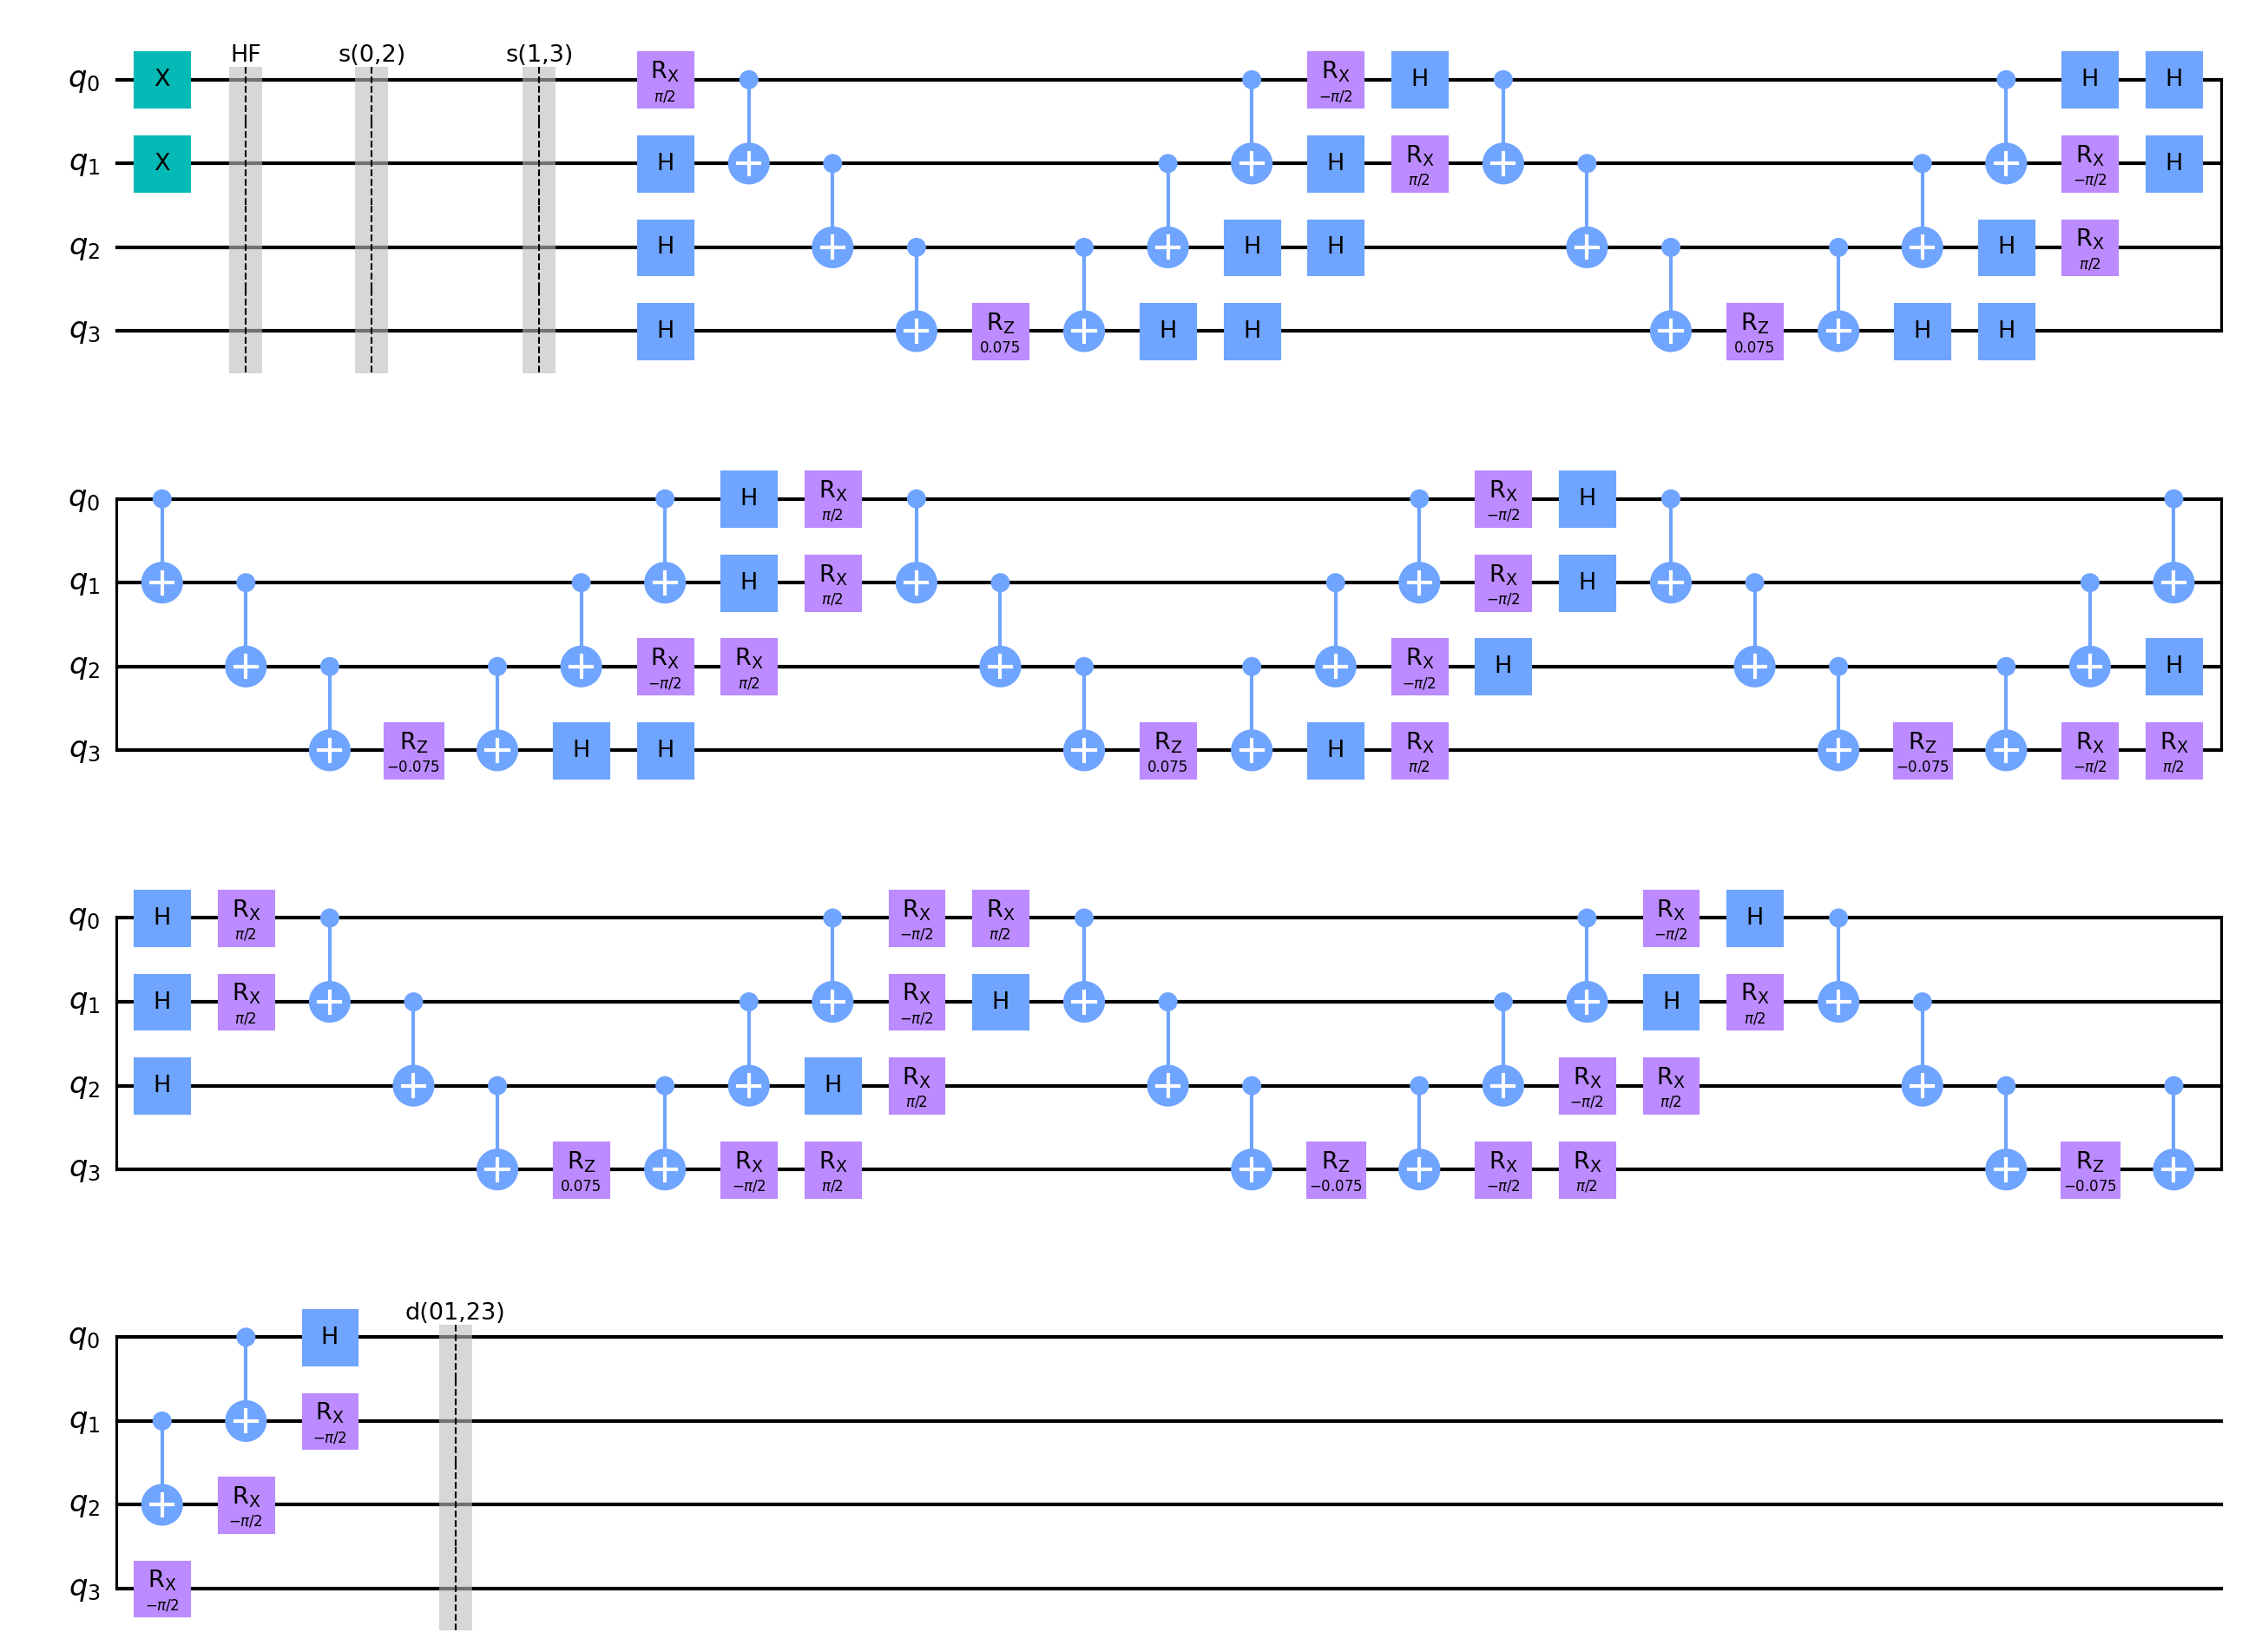

In [3]:
# ---- Circuit diagram (matplotlib) ----
fig = qc_state.draw(output="mpl", style={"name": "clifford"})
fig.savefig(f"{TOPIC_SLUG}_qiskit_circuit.png", dpi=150, bbox_inches="tight")
plt.close(fig)  # avoid relying on inline rich display, which can crash headless kernels
display(Image(f"{TOPIC_SLUG}_qiskit_circuit.png"))  # explicit, safe re-display from disk

In [4]:
# ---- Exact statevector + global-phase normalization ----
def normalize_global_phase(vec: np.ndarray) -> np.ndarray:
    '''Rotates so the first amplitude (ascending index/bitstring order) with |amp|>1e-9
    is real and positive. Identical function used in the CUDA-Q notebook.'''
    for amp in vec:
        if abs(amp) > 1e-9:
            phase = np.angle(amp)
            return vec * np.exp(-1j * phase)
    return vec

sv = Statevector.from_instruction(qc_state)
amps = normalize_global_phase(sv.data)

# Qiskit's own indexing already has qubit 0 as the LSB (rightmost bit) -> matches our
# ordering contract directly, ascending integer index == ascending bitstring order.
qiskit_prob_dict = {}
for i, amp in enumerate(amps):
    bitstring = format(i, f"0{N_QUBITS}b")   # qubit0 = rightmost char, no reversal needed
    prob = abs(amp) ** 2
    if prob > 1e-10:
        qiskit_prob_dict[bitstring] = round(prob, 6)

print("Statevector amplitudes (ascending bitstring order, phase-normalized):")
for i, amp in enumerate(amps):
    bitstring = format(i, f"0{N_QUBITS}b")
    if abs(amp) > 1e-9:
        print(f"  |{bitstring}>  amp = {amp:.6f}")

print("\nProbability dictionary (statevector, exact):")
print(dict(sorted(qiskit_prob_dict.items())))

Statevector amplitudes (ascending bitstring order, phase-normalized):
  |0011>  amp = 0.955336+0.000000j
  |1100>  amp = -0.295520-0.000000j

Probability dictionary (statevector, exact):
{'0011': np.float64(0.912668), '1100': np.float64(0.087332)}


**Ordering-fix note (Qiskit):** No reversal is applied. Qiskit's native
statevector/Operator indexing already treats qubit 0 as the least-significant (rightmost) bit
of the printed bitstring, which is exactly the ordering contract this pair of notebooks agreed
on — so the CUDA-Q notebook is the one that has to do the corrective work, not this one.


In [5]:
# ---- Sampling with shared SEED/SHOTS ----
qc_meas = build_uccsd_circuit(THETA_S0, THETA_S1, THETA_D, with_measurements=True)
sim = AerSimulator(seed_simulator=SEED)
job = sim.run(qc_meas, shots=SHOTS, seed_simulator=SEED)
counts = job.result().get_counts()

# Qiskit counts keys are already qubit0=rightmost -> no reversal needed.
qiskit_sampled_probs = {k: round(v / SHOTS, 6) for k, v in counts.items()}
print("Sampled probability dictionary (from counts):")
print(dict(sorted(qiskit_sampled_probs.items())))

Sampled probability dictionary (from counts):
{'0011': 0.915, '1100': 0.085}


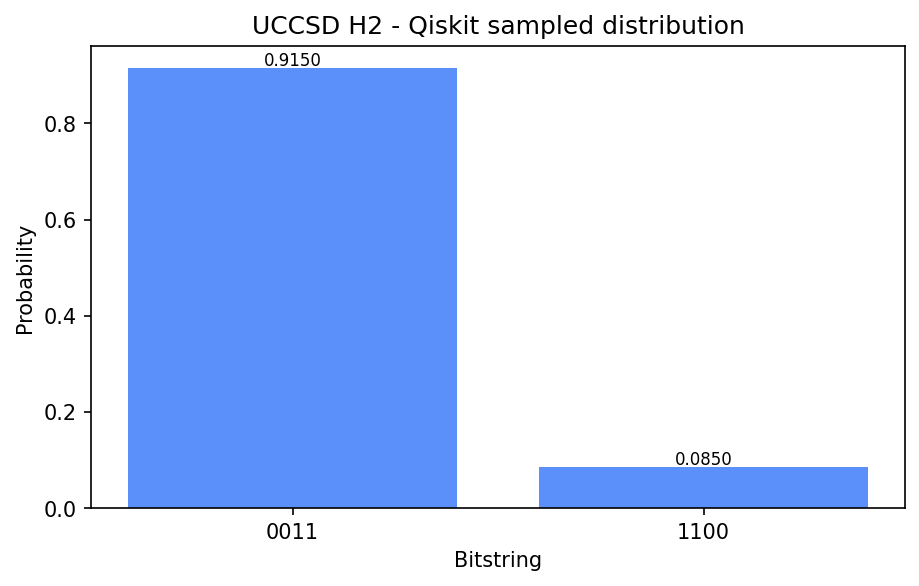

In [6]:
# ---- Histogram (plain matplotlib bar chart, safer than plot_histogram) ----
labels = sorted(counts.keys())
values = [counts[k] / SHOTS for k in labels]

fig2, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, values, color="#5B8FF9")
ax.set_title("UCCSD H2 - Qiskit sampled distribution")
ax.set_xlabel("Bitstring")
ax.set_ylabel("Probability")
for bar, v in zip(bars, values):
    if v > 0:
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.005, f"{v:.4f}", ha="center", fontsize=8)
fig2.savefig(f"{TOPIC_SLUG}_qiskit_histogram.png", dpi=150, bbox_inches="tight")
plt.close(fig2)  # avoid relying on inline rich display, which can crash headless kernels
display(Image(f"{TOPIC_SLUG}_qiskit_histogram.png"))  # explicit, safe re-display from disk

In [7]:
# ---- Resource counts ----
ops = qc_state.count_ops()
print("Gate counts:", dict(ops))
print("Depth:", qc_state.depth())
print("Total qubits:", qc_state.num_qubits)

Gate counts: {'cx': 48, 'rx': 32, 'h': 32, 'rz': 8, 'barrier': 4, 'x': 2}
Depth: 73
Total qubits: 4


**Convention notes (plain text):**
- Ordering: qubit 0 = rightmost bit throughout; Qiskit needed no reversal.
- Global phase: normalized so the first nonzero amplitude in ascending bitstring order is
  real and positive, via `vec * exp(-1j*angle(first_nonzero_amp))`.
- Ansatz: first-order-Trotterized JW UCCSD generator, HF reference `|0011>`,
  θ_s0=0.0, θ_s1=0.0, θ_d=0.30 rad.


In [8]:
# ---- Final result dict ----
QISKIT_RESULT = dict(sorted(qiskit_prob_dict.items()))
print("QISKIT_RESULT =", QISKIT_RESULT)

QISKIT_RESULT = {'0011': np.float64(0.912668), '1100': np.float64(0.087332)}


In [9]:
# ---- Diff-check against the CUDA-Q notebook's result ----
# Paste CUDAQ_RESULT from the companion notebook's final cell here, then uncomment:
#
# CUDAQ_RESULT = { ... }   # <- paste from the CUDA-Q notebook
# all_keys = set(QISKIT_RESULT) | set(CUDAQ_RESULT)
# max_delta = max(abs(QISKIT_RESULT.get(k, 0.0) - CUDAQ_RESULT.get(k, 0.0)) for k in all_keys)
# print("Max probability delta:", max_delta)
# assert max_delta < 1e-3, "Qiskit and CUDA-Q UCCSD results disagree beyond tolerance!"
#
# Hand-computed sanity check (verified exactly, not approximately, for this ansatz):
# with THETA_S0=THETA_S1=0.0, the double-excitation generator acts entirely within the
# invariant 2D subspace {|0011>, |1100>}, giving exactly
#   P(|0011>) = cos(THETA_D)^2 ,   P(|1100>) = sin(THETA_D)^2 ,   all other P = 0
import math
expected_0011 = math.cos(THETA_D) ** 2
expected_1100 = math.sin(THETA_D) ** 2
print(f"Expected: P(|0011>)={expected_0011:.6f}  P(|1100>)={expected_1100:.6f}")
print(f"Got     : P(|0011>)={QISKIT_RESULT.get('0011', 0.0):.6f}  "
      f"P(|1100>)={QISKIT_RESULT.get('1100', 0.0):.6f}")
assert abs(QISKIT_RESULT.get('0011', 0.0) - expected_0011) < 1e-3
assert abs(QISKIT_RESULT.get('1100', 0.0) - expected_1100) < 1e-3
print("Hand-computed sanity check passed.")


Expected: P(|0011>)=0.912668  P(|1100>)=0.087332
Got     : P(|0011>)=0.912668  P(|1100>)=0.087332
Hand-computed sanity check passed.
